# Poster figures — Project 3Regenerates every figure on the poster into `poster/figures/`.Run from the `Project3` folder with the project venv.| Section | Figures | Needs ||---|---|---|| Week 1 | `w1_umap_targets`, `w1_umap_neighbors`, `w1_probes` | `data/embeddings/` (already computed) || Week 2 | `w2_cell20_01` (Fig 4), `w2_cosine_strip` (Fig 5), `w2_tfidf` (Fig 6) | `week2/week2.ipynb` **run and saved** || Week 3 | `w3_t1…t4` | `week3/checkpoints/` + `week3/images/` |Week 2 is the odd one out: scoring the edited reports needs BioClinicalBERT, so those figures arelifted out of `week2/week2.ipynb` instead of recomputed. Run that notebook (Run All) and save itfirst. Week 1 and Week 3 recompute from scratch.Sections are independent — run only the one you want to tweak, after the Setup cell.

## Setup

In [1]:
from pathlib import Path
import base64, json, os, pickle, sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd()
if ROOT.name in ("week1", "week2", "week3"):   # in case the notebook is opened from a subfolder
    os.chdir("..")
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

OUT = ROOT / "poster" / "figures"
OUT.mkdir(parents=True, exist_ok=True)

# DTU colours
RED, BLUE, GREY, GREEN = "#990000", "#2F3EEA", "#9a9a9a", "#0A7A3E"
LABEL_COL = {"positive": RED, "negative": BLUE}

print("project root:", ROOT)
print("figures ->", OUT)

project root: /home/claude/p3
figures -> /home/claude/p3/poster/figures


---# Week 1 — what is in the representation?

In [2]:
import umap
from src.data import study_table, findings_texts, usable_findings, binary_label, top_k_classes
from src.embeddings import embedding_path, load_embeddings

studies = study_table()
X = load_embeddings(embedding_path("findings"), studies)
edema = binary_label(studies, "edema").map({1: "positive", 0: "negative"})
print("X", X.shape)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X (10000, 768)


### UMAP coordinatesCached in `poster/umaps.pkl` (~3 minutes the first time). Delete that file to recompute.

In [3]:
cache = ROOT / "poster" / "umaps.pkl"
if cache.exists():
    umaps = pickle.load(open(cache, "rb"))
else:
    umaps = {n: umap.UMAP(n_neighbors=n, random_state=0).fit_transform(X) for n in (5, 15, 200)}
    pickle.dump(umaps, open(cache, "wb"))
print("n_neighbors available:", list(umaps))

n_neighbors available: [5, 15, 200]


### Plot helpers`zoom` clips the axes to the core of the cloud. Without it the whole thing is one dot: a few per centof reports sit far out and stretch the axes. Widen `lo`/`hi` to show more of the outliers.

In [4]:
def zoom(ax, pts, lo=6.0, hi=94.0, pad=0.06):
    x0, x1 = np.percentile(pts[:, 0], [lo, hi])
    y0, y1 = np.percentile(pts[:, 1], [lo, hi])
    dx, dy = (x1 - x0) * pad, (y1 - y0) * pad
    ax.set_xlim(x0 - dx, x1 + dx)
    ax.set_ylim(y0 - dy, y1 + dy)


def plot_umap(ax, pts, values, title, legend=True, title_size=12, legend_size=8.5):
    values = pd.Series(values).reset_index(drop=True)
    known = values.notna().to_numpy()
    ax.scatter(*pts[~known].T, s=2.0, c="#e3e3e3", linewidths=0)        # missing / uncertain
    if pd.api.types.is_numeric_dtype(values) and values.nunique() > 10:
        d = ax.scatter(*pts[known].T, s=2.0, c=values[known], cmap="viridis", linewidths=0)
        cb = plt.colorbar(d, ax=ax, fraction=0.046, pad=0.02)
        cb.ax.tick_params(labelsize=9)
    else:
        for cls in sorted(values[known].unique()):
            m = (values == cls).to_numpy()
            ax.scatter(*pts[m].T, s=2.4, label=str(cls), linewidths=0, c=LABEL_COL.get(cls))
        if legend:
            ax.legend(markerscale=6, fontsize=legend_size, frameon=True, framealpha=0.85,
                      edgecolor="none", loc="lower right", handletextpad=0.1,
                      borderpad=0.2, labelspacing=0.25)
    zoom(ax, pts)
    ax.set_title(title, fontsize=title_size, fontweight="bold", pad=4)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color("#cccccc")

### Fig 1 — what the groups follow

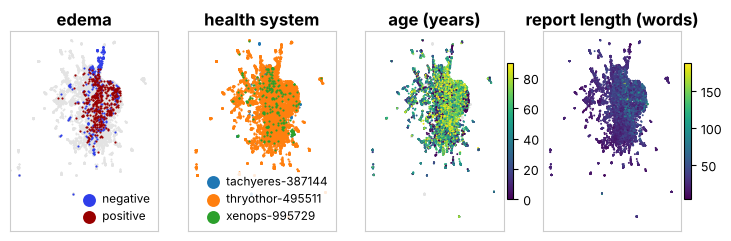

In [5]:
targets = {
    "edema": edema,
    "health system": studies["health_system"],
    "age (years)": studies["age_years"],
    "report length (words)": studies["findings_words"],
}

fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.3))
for ax, (name, v) in zip(axes, targets.items()):
    plot_umap(ax, umaps[15], v, name)
fig.tight_layout(pad=0.3)
fig.savefig(OUT / "w1_umap_targets.png", dpi=220)
plt.show()

### Fig 2 — the `n_neighbors` artefact

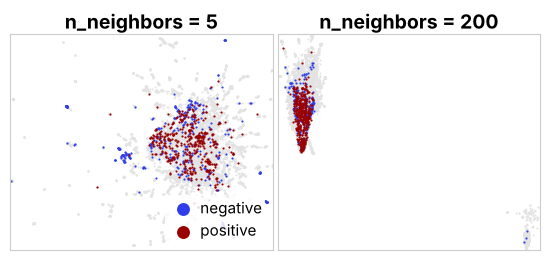

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.5))
for ax, n in zip(axes, (5, 200)):
    plot_umap(ax, umaps[n], edema, f"n_neighbors = {n}", legend=(n == 5),
              title_size=14, legend_size=11)
fig.tight_layout(pad=0.35)
fig.savefig(OUT / "w1_umap_neighbors.png", dpi=220)
plt.show()

### Linear probesPatient-wise 5-fold CV. The *kind* of target decides model, split and score, exactly as in `week1.ipynb`.Takes a couple of minutes (TF-IDF is the slow part). Add or remove rows in `targets` to probe something else.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, r2_score
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def probe(model, feats, y, groups, kind):
    folds = (GroupKFold(n_splits=5) if kind == "number"
             else StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0))
    preds = np.zeros(len(y))
    for tr, te in folds.split(feats, y, groups):
        model.fit(feats[tr], y[tr])
        preds[te] = (model.predict_proba(feats[te])[:, 1] if kind == "yes/no"
                     else model.predict(feats[te]))
    if kind == "yes/no":
        return roc_auc_score(y, preds)
    if kind == "classes":
        return balanced_accuracy_score(y, preds)
    return r2_score(y, preds)


def head(kind):
    return Ridge() if kind == "number" else LogisticRegression(max_iter=1000)


texts = np.array(findings_texts(studies), dtype=object)

targets = [
    # name,                 values,                                    kind,      chance
    ("edema",                 binary_label(studies, "edema"),            "yes/no",  0.5),
    ("pleural effusion",      binary_label(studies, "pleural_effusion"), "yes/no",  0.5),
    ("sex (F vs M)",          studies["sex"].map({"F": 1, "M": 0}),      "yes/no",  0.5),
    ("health system (3)",     studies["health_system"],                  "classes", 1 / 3),
    ("manufacturer (top 6)",  top_k_classes(studies["manufacturer"], 6), "classes", 1 / 6),
    ("age (years)",           studies["age_years"],                      "number",  0.0),
    ("study year",            studies["study_year"],                     "number",  0.0),
    ("report length (words)", studies["findings_words"],                 "number",  0.0),
]

rows = []
for name, values, kind, chance in targets:
    keep = (usable_findings(studies) & values.notna()).to_numpy()
    y = pd.factorize(values[keep])[0] if kind == "classes" else values[keep].to_numpy().astype(float)
    if kind == "yes/no":
        y = y.astype(int)
    groups = studies.loc[keep, "patient_id"].to_numpy()
    b = probe(make_pipeline(StandardScaler(), head(kind)), X[keep], y, groups, kind)
    t = probe(make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), head(kind)), texts[keep], y, groups, kind)
    rows.append({"target": name, "kind": kind, "n": int(keep.sum()),
                 "chance": chance, "BERT": round(b, 3), "TF-IDF": round(t, 3)})
    print(rows[-1], flush=True)

res = pd.DataFrame(rows)
res.to_csv(OUT / "w1_probe_results.csv", index=False)
res

{'target': 'edema', 'kind': 'yes/no', 'n': 851, 'chance': 0.5, 'BERT': 0.919, 'TF-IDF': 0.946}


{'target': 'pleural effusion', 'kind': 'yes/no', 'n': 784, 'chance': 0.5, 'BERT': 0.914, 'TF-IDF': 0.928}


{'target': 'sex (F vs M)', 'kind': 'yes/no', 'n': 9870, 'chance': 0.5, 'BERT': 0.545, 'TF-IDF': 0.557}


{'target': 'health system (3)', 'kind': 'classes', 'n': 10000, 'chance': 0.3333333333333333, 'BERT': 0.676, 'TF-IDF': 0.508}


{'target': 'manufacturer (top 6)', 'kind': 'classes', 'n': 9271, 'chance': 0.16666666666666666, 'BERT': 0.439, 'TF-IDF': 0.456}


{'target': 'age (years)', 'kind': 'number', 'n': 9582, 'chance': 0.0, 'BERT': 0.43, 'TF-IDF': 0.506}


{'target': 'study year', 'kind': 'number', 'n': 10000, 'chance': 0.0, 'BERT': 0.338, 'TF-IDF': 0.474}


{'target': 'report length (words)', 'kind': 'number', 'n': 10000, 'chance': 0.0, 'BERT': 0.96, 'TF-IDF': 0.835}


,target,kind,n,chance,BERT,TF-IDF
0,edema,yes/no,851,0.500000,0.919,0.946
1,pleural effusion,yes/no,784,0.500000,0.914,0.928
2,sex (F vs M),yes/no,9870,0.500000,0.545,0.557
3,health system (3),classes,10000,0.333333,0.676,0.508
4,manufacturer (top 6),classes,9271,0.166667,0.439,0.456
5,age (years),number,9582,0.000000,0.430,0.506
6,study year,number,10000,0.000000,0.338,0.474
7,report length (words),number,10000,0.000000,0.960,0.835


### Fig 3 — probe results

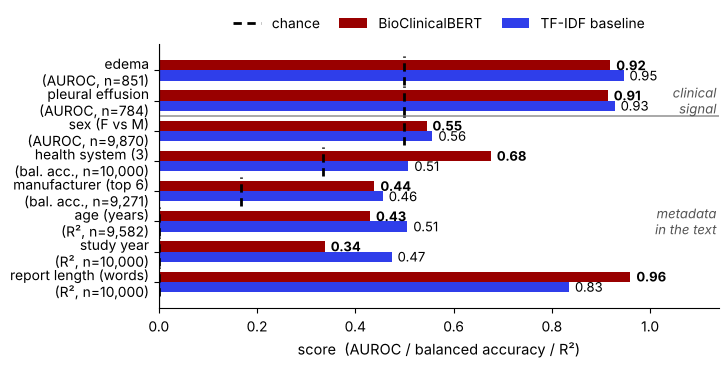

In [8]:
SCORE = {"yes/no": "AUROC", "classes": "bal. acc.", "number": "R²"}

fig, ax = plt.subplots(figsize=(7.2, 3.6))
yp = np.arange(len(res))[::-1]
h = 0.34
ax.barh(yp + h / 2, res["BERT"], h, color=RED, label="BioClinicalBERT")
ax.barh(yp - h / 2, res["TF-IDF"], h, color=BLUE, label="TF-IDF baseline")
for i, r in res.iterrows():
    yy = yp[i]
    ax.plot([r["chance"]] * 2, [yy - 0.48, yy + 0.48], color="black", lw=2,
            ls=(0, (3, 2)), zorder=5, label="chance" if i == 0 else None)
    ax.text(max(r["BERT"], 0) + 0.012, yy + h / 2, f"{r['BERT']:.2f}",
            va="center", fontsize=9.5, fontweight="bold")
    ax.text(max(r["TF-IDF"], 0) + 0.012, yy - h / 2, f"{r['TF-IDF']:.2f}",
            va="center", fontsize=9.5)

ax.set_yticks(yp, [f"{r.target}\n({SCORE[r.kind]}, n={r.n:,})" for r in res.itertuples()], fontsize=10)
ax.set_xlim(0, 1.14)
ax.set_xlabel("score  (AUROC / balanced accuracy / R²)", fontsize=10.5)
ax.axvline(0, color="black", lw=0.8)
ax.axhline(yp[2] + 0.5, color="#999999", lw=1.2)              # clinical | metadata divider
ax.text(1.135, yp[1], "clinical\nsignal", fontsize=9.5, style="italic",
        ha="right", va="center", color="#555555")
ax.text(1.135, yp[5], "metadata\nin the text", fontsize=9.5, style="italic",
        ha="right", va="center", color="#555555")
ax.legend(fontsize=10, frameon=False, ncol=3, loc="lower center",
          bbox_to_anchor=(0.5, 1.0), columnspacing=1.4)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", labelsize=10)
fig.tight_layout(pad=0.4)
fig.savefig(OUT / "w1_probes.png", dpi=220)
plt.show()

---# Week 2 — does it react to the right change?Figures 4 and 5 come out of `week2/week2.ipynb`, so **run that notebook and save it first**.Fig 5 on the poster is only the right-hand panel of the notebook's two-panel figure: the 4-reportUMAP on the left does not survive being shrunk to a poster column, and placing new points into afitted UMAP is approximate anyway.

In [9]:
nb_path = ROOT / "week2" / "week2.ipynb"
nb = json.load(open(nb_path))
pngs = [o["data"]["image/png"] for c in nb["cells"] for o in c.get("outputs", [])
        if "image/png" in o.get("data", {})]
assert len(pngs) >= 2, f"{nb_path} has {len(pngs)} figures — run it (Run All) and save it first."

(OUT / "w2_cell20_01.png").write_bytes(base64.b64decode(pngs[0]))     # Fig 4, used as-is
strip_src = OUT / "w2_cell23_02.png"
strip_src.write_bytes(base64.b64decode(pngs[1]))
print("pulled", len(pngs), "figures out of week2.ipynb")

pulled 2 figures out of week2.ipynb


### Fig 5 — crop the cosine-shift panel

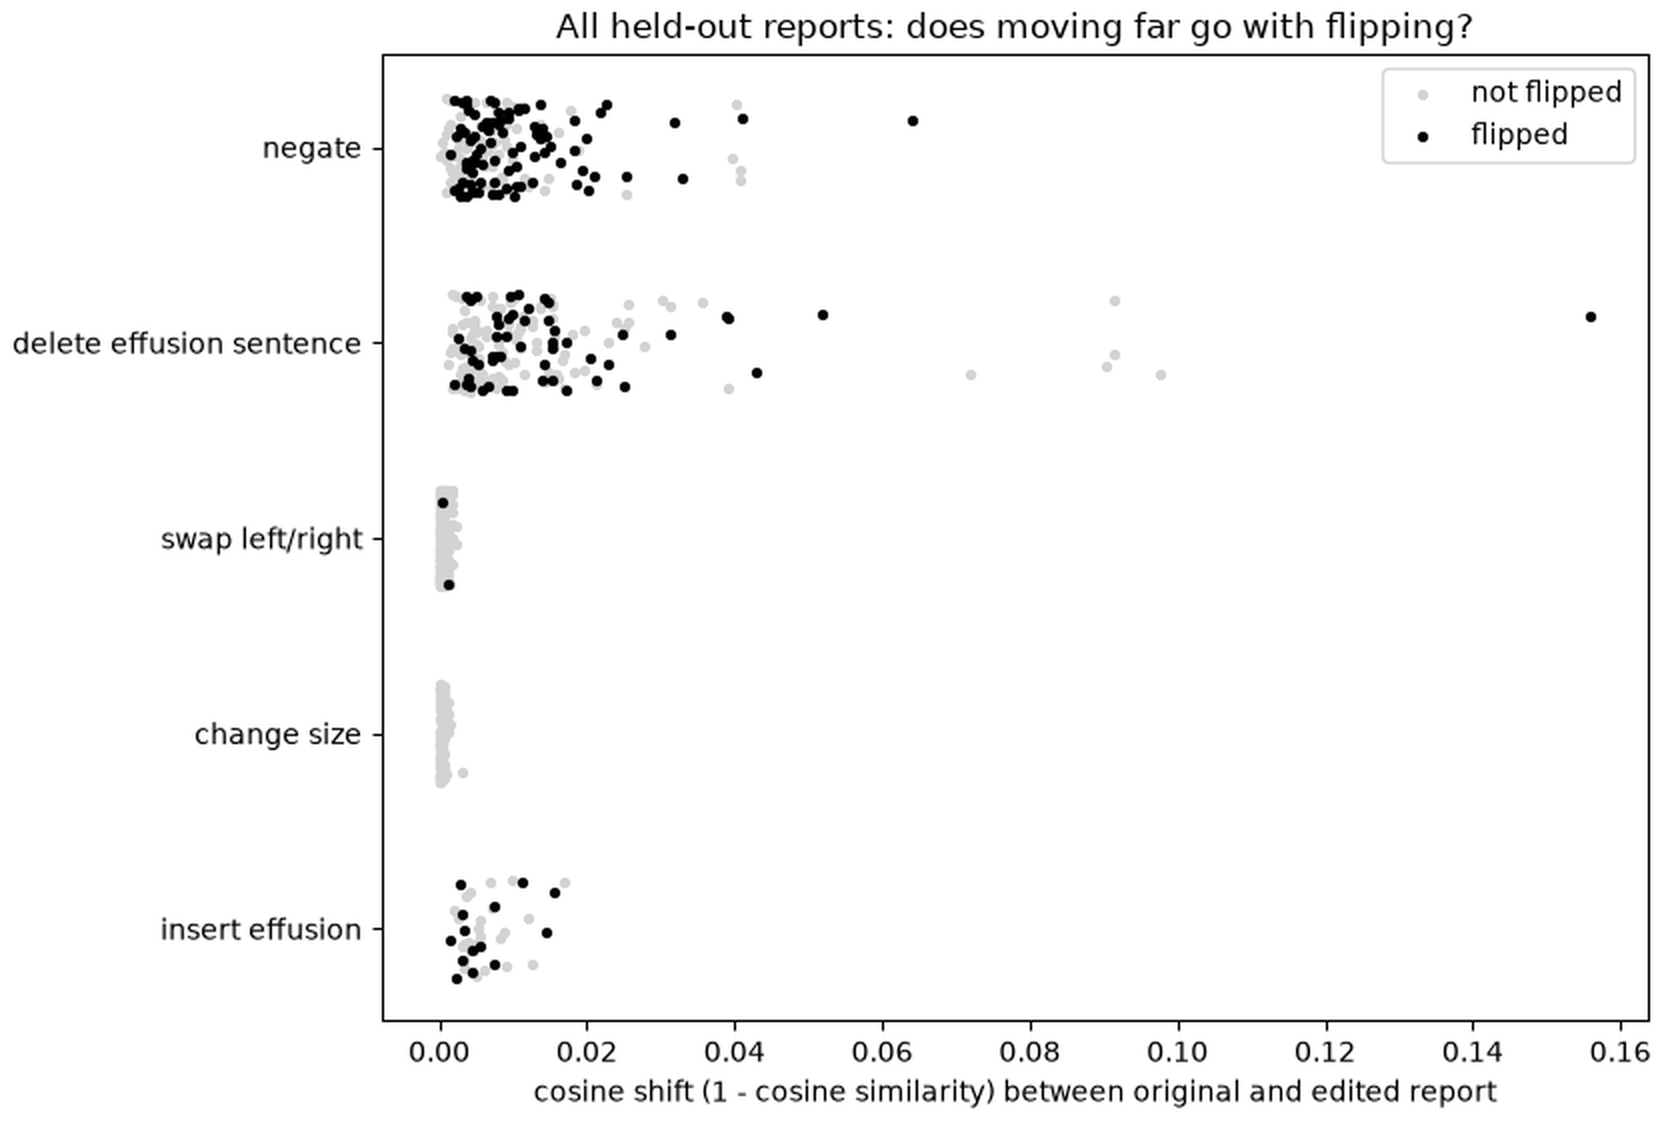

In [10]:
CROP_X = 652          # left edge of the right-hand panel; lower it if the y-labels get clipped

im = Image.open(strip_src).convert("RGB")
crop = im.crop((CROP_X, 0, im.width, im.height))
a = np.array(crop)
ys = np.where((a.min(2) < 245).sum(1) > 0)[0]                 # trim blank rows
crop = crop.crop((0, max(0, ys.min() - 6), crop.width, min(crop.height, ys.max() + 8)))
crop = crop.resize((crop.width * 2, crop.height * 2), Image.LANCZOS)   # upscale for A0 print
crop.save(OUT / "w2_cosine_strip.png")
crop

### Fig 6 — BERT vs TF-IDF flip ratesNumbers come from the TF-IDF cell at the end of `week2.ipynb`. Update the two lists if they change.

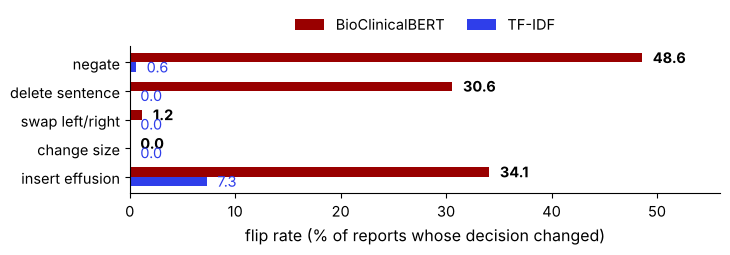

In [11]:
EDIT_NAMES = ["negate", "delete sentence", "swap left/right", "change size", "insert effusion"]
BERT_FLIP  = [0.486, 0.306, 0.012, 0.000, 0.341]
TFIDF_FLIP = [0.006, 0.000, 0.000, 0.000, 0.073]

fig, ax = plt.subplots(figsize=(7.2, 2.45))
y = np.arange(len(EDIT_NAMES))[::-1]
h = 0.33
ax.barh(y + h / 2, [v * 100 for v in BERT_FLIP], h, color=RED, label="BioClinicalBERT")
ax.barh(y - h / 2, [v * 100 for v in TFIDF_FLIP], h, color=BLUE, label="TF-IDF")
for i, (b, t) in enumerate(zip(BERT_FLIP, TFIDF_FLIP)):
    ax.text(b * 100 + 1.0, y[i] + h / 2, f"{b * 100:.1f}", va="center", fontsize=10.5, fontweight="bold")
    ax.text(t * 100 + 1.0, y[i] - h / 2, f"{t * 100:.1f}", va="center", fontsize=10.5, color=BLUE)
ax.set_yticks(y, EDIT_NAMES, fontsize=11.5)
ax.set_xlabel("flip rate (% of reports whose decision changed)", fontsize=11.5)
ax.set_xlim(0, 56)
ax.legend(fontsize=10.5, frameon=False, ncol=2, loc="lower center",
          bbox_to_anchor=(0.5, 1.0), columnspacing=1.5)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(labelsize=10.5)
fig.tight_layout(pad=0.35)
fig.savefig(OUT / "w2_tfidf.png", dpi=220)
plt.show()

---# Week 3 — where does a chest X-ray model look?CPU only, no downloads: the three DenseNet-121 checkpoints are local and `load_model.py` builds thearchitecture with `weights=None`.

In [12]:
import torch
import torch.nn.functional as F
from PIL import ImageDraw, ImageFont

# Pin the font so tight_layout places the panels identically on any machine.
plt.rcParams.update({"font.family": "DejaVu Sans"})

os.chdir(ROOT / "week3")                     # load_model.py and images/ resolve relative to week3/
sys.path.insert(0, str(ROOT / "week3"))
from load_model import load_model, preprocess

IMG = ROOT / "week3" / "images"            # absolute, so cells can be re-run in any order
info = pd.read_csv(ROOT / "week3" / "images.csv")
models = {n: load_model(n) for n in ["Cardiomegaly", "Edema", "Atelectasis"]}
print("loaded:", list(models))

loaded: ['Cardiomegaly', 'Edema', 'Atelectasis']


### Grad-CAM and the panel helperThe heatmap is scaled to its own maximum, so **every** map has a red spot — always read it next to thescore, which is printed in the bottom-left corner of each panel
(bottom, so it does not hide the stamped text in test 3). The label/view tag sits top-right.

In [13]:
def gradcam(model, x):
    feats = model.features(x)                              # [1, 1024, 8, 8]
    feats.retain_grad()
    pooled = F.adaptive_avg_pool2d(F.relu(feats), 1).flatten(1)
    logit = model.classifier(pooled)[0, 0]                 # the positive logit
    logit.backward()                                       # no no_grad(): we need gradients
    w = feats.grad.mean(dim=(2, 3), keepdim=True)          # one weight per feature map
    cam = F.relu((w * feats).sum(dim=1))[0]                # keep only what pushes the logit up
    cam = cam / (cam.max() + 1e-8)                         # <- the per-map scaling
    return logit.item(), cam.detach().numpy()


def score_of(logit):
    return torch.sigmoid(torch.tensor(logit)).item()


def panel(ax, image, cam, score, tag=None, tagcolor="white"):
    ax.imshow(image.convert("L").resize((256, 256)), cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.4, extent=(0, 256, 256, 0), interpolation="bilinear")
    ax.text(0.02, 0.02, f"score {score:.2f}", transform=ax.transAxes, va="bottom", ha="left",
            fontsize=12, fontweight="bold", color="white",
            bbox=dict(boxstyle="square,pad=0.25", fc="black", ec="none", alpha=0.65))
    if tag:
        ax.text(0.98, 0.98, tag, transform=ax.transAxes, va="top", ha="right",
                fontsize=10, color=tagcolor,
                bbox=dict(boxstyle="square,pad=0.22", fc="black", ec="none", alpha=0.6))
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color("#bbbbbb")

### Fig 4 — test 1: same images, three models

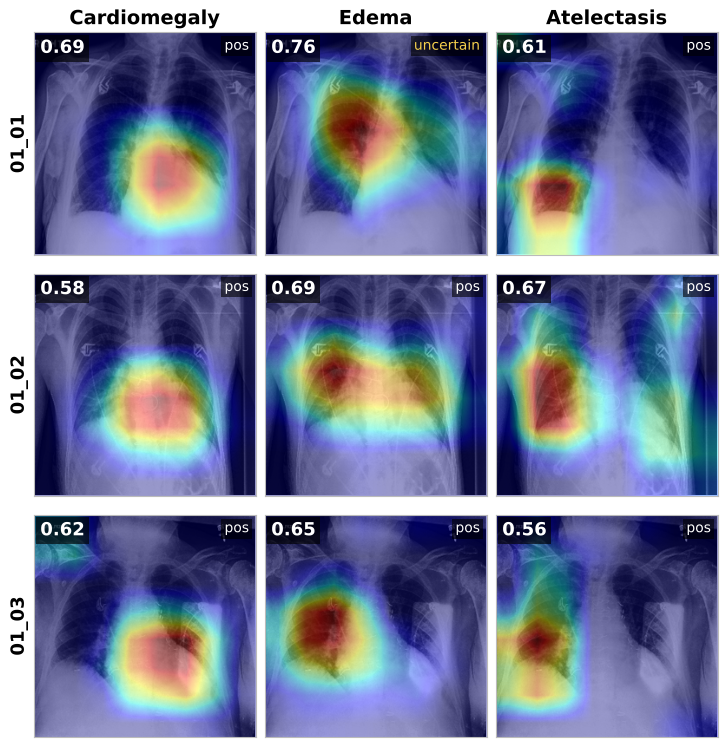

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(7.2, 7.6))
for i, name in enumerate(["01_01", "01_02", "01_03"]):
    image = Image.open(IMG / f"01_compare_models/{name}_original.jpg").convert("RGB")
    x = preprocess(image)
    row = info[info.image_id == f"{name}_original"].iloc[0]
    for j, (pathology, model) in enumerate(models.items()):
        logit, cam = gradcam(model, x)
        lab = row[pathology]
        tag = "label: " + {1.0: "positive", -1.0: "uncertain"}.get(lab, "not mentioned")
        panel(axes[i, j], image, cam, score_of(logit), tag, "#F6D04D" if lab == -1.0 else "white")
        if i == 0:
            axes[i, j].set_title(pathology, fontsize=14, fontweight="bold", pad=6)
    axes[i, 0].set_ylabel(name, fontsize=13, fontweight="bold")
fig.subplots_adjust(wspace=0.04, hspace=0.04, left=0.045, right=0.995, top=0.945, bottom=0.005)
fig.savefig(OUT / "w3_t1_models.png", dpi=200)
plt.show()

### Fig 5 — test 2: positives vs negatives

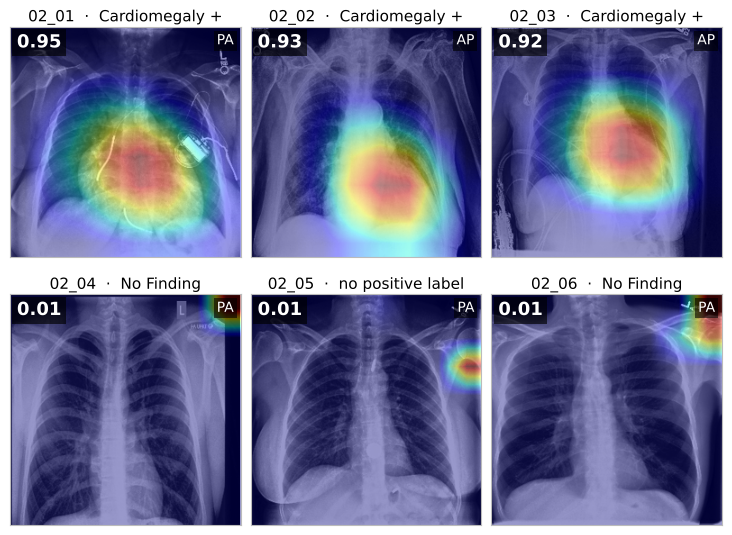

In [15]:
model = models["Cardiomegaly"]

fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.3))
for ax, k in zip(axes.flat, range(1, 7)):
    name = f"02_0{k}"
    image = Image.open(IMG / f"02_positive_negative/{name}_original.jpg").convert("RGB")
    row = info[info.image_id == f"{name}_original"].iloc[0]
    logit, cam = gradcam(model, preprocess(image))
    panel(ax, image, cam, score_of(logit), f"view: {row.view}")
    lab = "Cardiomegaly +" if k <= 3 else ("No Finding" if k in (4, 6) else "no positive label")
    ax.set_title(f"{name}  ·  {lab}", fontsize=11, pad=4)
fig.subplots_adjust(wspace=0.04, hspace=0.16, left=0.005, right=0.995, top=0.945, bottom=0.005)
fig.savefig(OUT / "w3_t2_posneg.png", dpi=200)
plt.show()

### Test 3 — text shortcut`HEJ MED DIG` is the control: same length and position as `PORTABLE AP`, no meaning. If both raise thescore by the same amount, the effect is bright pixels in the corner, not the words.Change `SHOW_ROWS` to pick which images get a map panel — all four are always scored.

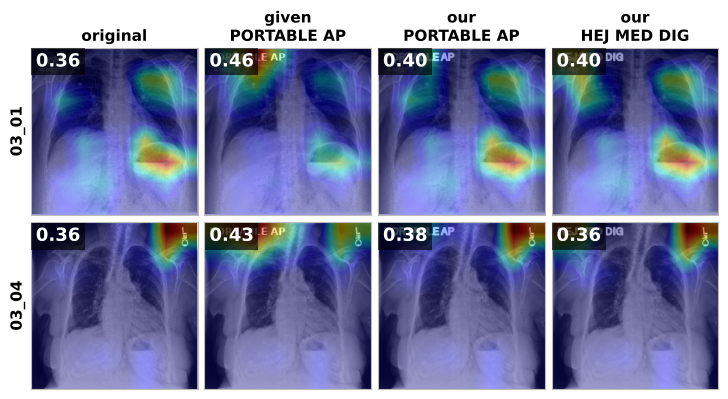

,original,given PORTABLE AP,our PORTABLE AP,our HEJ MED DIG
image,,,,
03_01,0.359,0.458,0.402,0.399
03_02,0.252,0.341,0.297,0.312
03_03,0.262,0.331,0.276,0.263
03_04,0.362,0.431,0.377,0.362


In [16]:
model = models["Atelectasis"]
FONT = ImageFont.load_default(size=16)
SHOW_ROWS = [1, 4]


def add_text(image, text):
    """Resize first, then stamp: the edit has to happen before normalisation."""
    image = image.resize((256, 256), Image.Resampling.BILINEAR)
    ImageDraw.Draw(image).text((9, 9), text, font=FONT, fill="white", anchor="lt", stroke_width=1)
    return image


rows3 = []
fig, axes = plt.subplots(len(SHOW_ROWS), 4, figsize=(7.2, 4.0))
for k in range(1, 5):
    original = Image.open(IMG / f"03_text_shortcut/03_0{k}_original.jpg").convert("RGB")
    variants = {
        "original": original,
        "given\nPORTABLE AP": Image.open(IMG / f"03_text_shortcut/03_0{k}_text.png").convert("RGB"),
        "our\nPORTABLE AP": add_text(original, "PORTABLE AP"),
        "our\nHEJ MED DIG": add_text(original, "HEJ MED DIG"),
    }
    r = {"image": f"03_0{k}"}
    for j, (variant, image) in enumerate(variants.items()):
        logit, cam = gradcam(model, preprocess(image))
        sc = score_of(logit)
        r[variant.replace("\n", " ")] = round(sc, 3)
        if k in SHOW_ROWS:
            ax = axes[SHOW_ROWS.index(k), j]
            panel(ax, image, cam, sc)
            if SHOW_ROWS.index(k) == 0:
                ax.set_title(variant, fontsize=11, fontweight="bold", pad=5)
            if j == 0:
                ax.set_ylabel(f"03_0{k}", fontsize=11, fontweight="bold")
    rows3.append(r)

fig.subplots_adjust(wspace=0.04, hspace=0.04, left=0.04, right=0.995, top=0.86, bottom=0.005)
fig.savefig(OUT / "w3_t3_textmaps.png", dpi=200)
plt.show()

t3 = pd.DataFrame(rows3).set_index("image")
t3.to_csv(OUT / "w3_t3_scores.csv")
t3

### Fig 6 — test 3: score change

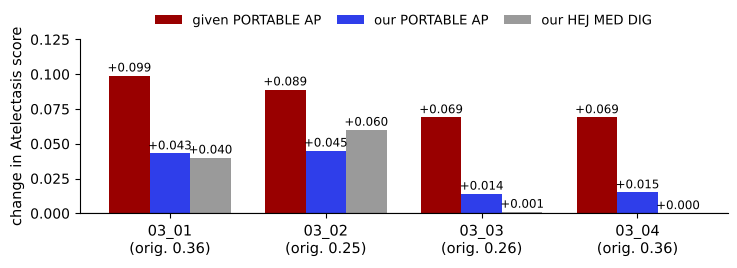

mean change: {'given PORTABLE AP': 0.082, 'our PORTABLE AP': 0.029, 'our HEJ MED DIG': 0.025}


In [17]:
labels3 = ["given PORTABLE AP", "our PORTABLE AP", "our HEJ MED DIG"]

fig, ax = plt.subplots(figsize=(7.2, 2.6))
x = np.arange(len(t3)); w = 0.26
for i, (lab, c) in enumerate(zip(labels3, [RED, BLUE, GREY])):
    d = (t3[lab] - t3["original"]).values
    ax.bar(x + (i - 1) * w, d, w, label=lab, color=c)
    for xi, di in zip(x + (i - 1) * w, d):
        ax.text(xi, di + 0.003, f"{di:+.03f}", ha="center", fontsize=8.5)
ax.set_xticks(x, [f"{i}\n(orig. {t3.loc[i, 'original']:.2f})" for i in t3.index], fontsize=10.5)
ax.set_ylabel("change in Atelectasis score", fontsize=10.5)
ax.set_ylim(0, 0.125)
ax.axhline(0, color="black", lw=0.8)
ax.legend(fontsize=9.5, frameon=False, ncol=3, loc="lower center",
          bbox_to_anchor=(0.5, 1.0), columnspacing=1.2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(pad=0.4)
fig.savefig(OUT / "w3_t3_delta.png", dpi=220)
plt.show()

print("mean change:", (t3[labels3].mean() - t3["original"].mean()).round(3).to_dict())

### Test 4 — occlusionBoxes are hand-drawn on the 256×256 image, `(x0, y0, x1, y1)`. `big lung` matches the heart box inarea, so a bigger drop for the heart cannot be explained by box size alone.**Move them if you disagree** — run the preview cell below to see where they sit.

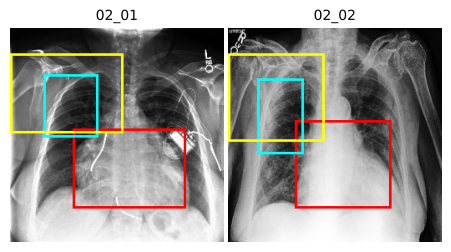

In [18]:
BOXES = {
    "02_01": {"heart": (75, 120, 210, 215), "lung": (40, 55, 105, 130), "big lung": (0, 30, 135, 125)},
    "02_02": {"heart": (80, 110, 195, 215), "lung": (35, 60, 90, 150), "big lung": (0, 30, 115, 135)},
}

fig, axes = plt.subplots(1, 2, figsize=(4.4, 2.3))
for ax, (name, boxes) in zip(axes, BOXES.items()):
    image = Image.open(IMG / f"02_positive_negative/{name}_original.jpg").convert("RGB").resize((256, 256))
    d = ImageDraw.Draw(image)
    d.rectangle(boxes["heart"], outline="red", width=3)        # heart
    d.rectangle(boxes["lung"], outline="cyan", width=3)        # small lung control
    d.rectangle(boxes["big lung"], outline="yellow", width=3)  # same-area lung control
    ax.imshow(image); ax.set_title(name, fontsize=10); ax.axis("off")
fig.tight_layout(pad=0.3)
fig.savefig(OUT / "w3_t4_boxes.png", dpi=200)
plt.show()

### Fig 7 — test 4: hide the heart, hide a lung

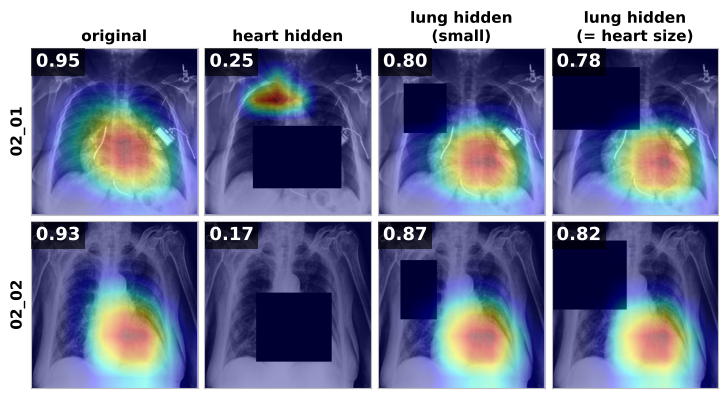

,original,heart hidden,lung hidden (small),lung hidden (= heart size)
image,,,,
02_01,0.955,0.255,0.804,0.780
02_02,0.927,0.167,0.868,0.817


In [19]:
model = models["Cardiomegaly"]


def occlude(image, box):
    image = image.resize((256, 256), Image.Resampling.BILINEAR)
    ImageDraw.Draw(image).rectangle(box, fill="black")
    return image


rows4 = []
fig, axes = plt.subplots(2, 4, figsize=(7.2, 4.0))
for i, (name, boxes) in enumerate(BOXES.items()):
    original = Image.open(IMG / f"02_positive_negative/{name}_original.jpg").convert("RGB")
    variants = {
        "original": original,
        "heart hidden": occlude(original, boxes["heart"]),
        "lung hidden\n(small)": occlude(original, boxes["lung"]),
        "lung hidden\n(= heart size)": occlude(original, boxes["big lung"]),
    }
    r = {"image": name}
    for j, (variant, image) in enumerate(variants.items()):
        logit, cam = gradcam(model, preprocess(image))
        sc = score_of(logit)
        r[variant.replace("\n", " ")] = round(sc, 3)
        panel(axes[i, j], image, cam, sc)
        if i == 0:
            axes[i, j].set_title(variant, fontsize=11, fontweight="bold", pad=5)
        if j == 0:
            axes[i, j].set_ylabel(name, fontsize=11, fontweight="bold")
    rows4.append(r)

fig.subplots_adjust(wspace=0.04, hspace=0.04, left=0.04, right=0.995, top=0.855, bottom=0.005)
fig.savefig(OUT / "w3_t4_occlusion.png", dpi=200)
plt.show()

t4 = pd.DataFrame(rows4).set_index("image")
t4.to_csv(OUT / "w3_t4_scores.csv")
t4

### Fig 7b — test 4: scores

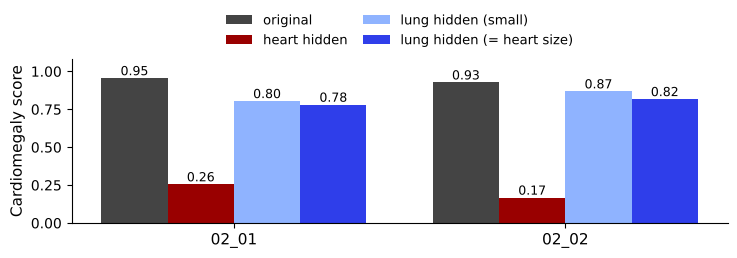

all figures written to /home/claude/p3/poster/figures


In [20]:
labels4 = ["original", "heart hidden", "lung hidden (small)", "lung hidden (= heart size)"]

fig, ax = plt.subplots(figsize=(7.2, 2.5))
x = np.arange(len(t4)); w = 0.2
for i, (lab, c) in enumerate(zip(labels4, ["#444444", RED, "#8fb3ff", BLUE])):
    v = t4[lab].values
    ax.bar(x + (i - 1.5) * w, v, w, label=lab, color=c)
    for xi, vi in zip(x + (i - 1.5) * w, v):
        ax.text(xi, vi + 0.02, f"{vi:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, t4.index, fontsize=11)
ax.set_ylabel("Cardiomegaly score", fontsize=11)
ax.set_ylim(0, 1.08)
ax.legend(fontsize=9.5, frameon=False, ncol=2, loc="lower center",
          bbox_to_anchor=(0.5, 1.0), columnspacing=1.2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(pad=0.4)
fig.savefig(OUT / "w3_t4_delta.png", dpi=220)
plt.show()

os.chdir(ROOT)      # back to the project root
print("all figures written to", OUT)

---## Rebuilding the posterThe poster embeds the PNGs, so after regenerating a figure rebuild it:```bashpython poster/build_poster.py```That prints a fit report (slack in pt per box) — a negative number means that box overflows its card,so shrink a figure or trim a bullet.